##Atividade Prática: Consumo de Dados de Saúde via API
Aluna: *Beatriz Pereira Goulart*


**1. Preparação do Ambiente**

Nesta etapa, importamos as bibliotecas necessárias. O requests fará a comunicação com o servidor do governo, o pandas organizará os dados em tabelas (DataFrames) e o matplotlib/seaborn criarão a visualização gráfica.



In [ ]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_theme(style="whitegrid")

**2. Autenticação e Requisição**

Aqui configuramos o Token e a URL do endpoint de Ocupação Hospitalar. Utilizamos a biblioteca requests para buscar os dados em tempo real.

In [ ]:
API_KEY = "a8b584777a6d31e4bf1fea3e2336c29c"
URL_DADOS = "https://apidadosabertos.saude.gov.br/assistencia-a-saude/registro-de-ocupacao-hospitalar-covid-19?limit=200"

headers = {
    "accept": "application/json",
    "chave-api-dados": API_KEY
}

response = requests.get(URL_DADOS, headers=headers, timeout=30)
print(f"Status da Requisição: {response.status_code}")

Status da Requisição: 200


**3. Tratamento e Limpeza de Dados**

Após receber a resposta, convertemos o conteúdo de JSON para um DataFrame. Realizamos uma limpeza para garantir que os valores de ocupação sejam numéricos e filtramos as colunas de Estado e Ocupação.

In [ ]:
# Conversão de JSON para DataFrame
dados_json = response.json()
chave_principal = list(dados_json.keys())[0]
df = pd.DataFrame(dados_json[chave_principal])

# Identificação dinâmica de colunas para evitar erros de nomes
col_estado = [c for c in df.columns if 'estado' in c.lower()][0]
col_uti = [c for c in df.columns if 'uti' in c.lower() or 'ocupacao' in c.lower()][0]

# Limpeza: Convertendo valores para números e tratando campos vazios
df[col_uti] = pd.to_numeric(df[col_uti], errors='coerce').fillna(0)

# Agrupando os dados por Estado para uma análise mais significativa
ranking = df.groupby(col_estado)[col_uti].sum().sort_values(ascending=False).reset_index()

**4. Visualização dos Resultados**

Por fim, geramos um gráfico de barras para visualizar quais estados possuem o maior volume de ocupação hospitalar registrada no momento da consulta.

/tmp/ipykernel_2515/1074519546.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=ranking.head(15), x=col_uti, y=col_estado, palette='magma')


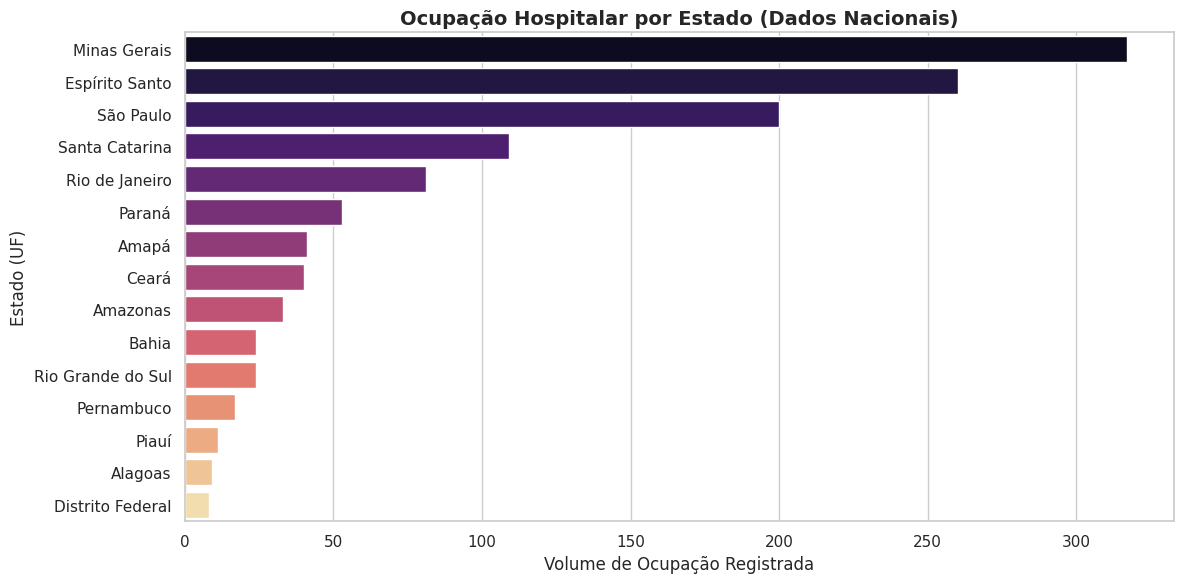

,estado,ocupacaoconfirmadocli
0,Minas Gerais,317.0
1,Espírito Santo,260.0
2,São Paulo,200.0
3,Santa Catarina,109.0
4,Rio de Janeiro,81.0
5,Paraná,53.0
6,Amapá,41.0
7,Ceará,40.0
8,Amazonas,33.0
9,Bahia,24.0


In [ ]:
plt.figure(figsize=(12, 6))
sns.barplot(data=ranking.head(15), x=col_uti, y=col_estado, palette='magma')

plt.title('Ocupação Hospitalar por Estado (Dados Nacionais)', fontsize=14, fontweight='bold')
plt.xlabel('Volume de Ocupação Registrada', fontsize=12)
plt.ylabel('Estado (UF)', fontsize=12)
plt.tight_layout()
plt.show()

display(ranking.head(27))

##Conclusão

Os dados extraídos revelam que a ocupação hospitalar não é uniforme, apresentando picos de demanda em estados com maior densidade populacional. A variação dos números entre as regiões destaca a importância do monitoramento contínuo: enquanto estados com grandes centros urbanos mostram maior pressão no sistema, regiões com menores índices podem indicar tanto uma situação estável quanto eventuais atrasos na atualização dos dados (subnotificação).